In [2]:
PEPTIDE = "AAAAAA"

# Frames are chosen up front: the k-th saved frame of every trajectory.
FRAMES = [1, 10, 100, 999]

N_REF = 10_000                 # size of the strided MD-reference subsample
SAMPLE_DIR = f"robin_samples/{PEPTIDE}"
TRAJ_DIR = f"robin_md_trajectories/{PEPTIDE}"

In [3]:
from src.data.single_peptide_datamodule import SinglePeptideDataModule

dm = SinglePeptideDataModule(
    repo_id="transferable-samplers/sequential-boltzmann-generators-data",
    data_dir="data", sequence=PEPTIDE, temperature=310, num_dimensions=3, num_atoms=0,
)
dm.prepare_data()
dm.setup()
pot = dm.setup_potential()

md_ref = dm.data_test.data
md_ref = md_ref[:: max(1, len(md_ref) // N_REF)][:N_REF]
E_md_ref = pot.energy(md_ref).flatten()

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

In [11]:
dm.topology

<mdtraj.Topology with 1 chains, 6 residues, 63 atoms, 62 bonds at 0x733b77080ad0>

In [5]:
import glob
import torch
import numpy as np
import openmm.app as app

sample_files = sorted(glob.glob(f"{SAMPLE_DIR}/{PEPTIDE}_*.pdb"))
proposal_positions = torch.tensor(
    np.stack([app.PDBFile(f).getPositions(asNumpy=True)._value for f in sample_files]),
    dtype=torch.float64,
)

In [6]:
import contextlib
import sys
import os
from mdtraj.formats import DCDTrajectoryFile

@contextlib.contextmanager
def quiet_stdout():
    """The DCD plugin prints two info lines per file on fd 1; silence them."""
    sys.stdout.flush()
    saved, devnull = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        sys.stdout.flush()
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


def load_frame(frame, files):
    """Positions (nm) of one DCD frame for every trajectory, in dm.topology order."""
    coords = []
    with quiet_stdout():
        for f in files:
            with DCDTrajectoryFile(f) as dcd:
                dcd.seek(frame)
                xyz, _, _ = dcd.read(1)   # Angstroms in the file
            coords.append(xyz[0] * 0.1)   # Angstrom -> nanometer
    return torch.tensor(np.stack(coords), dtype=torch.float64)


traj_files = sorted(glob.glob(f"{TRAJ_DIR}/[0-9][0-9][0-9][0-9][0-9]/traj.dcd"))
print(f"{len(traj_files)} MD trajectories found")
proposal_md_positions = load_frame(FRAMES[0], traj_files)

200 MD trajectories found


In [7]:
dm.prepare_eval("", "test")

(tensor([[[ 1.2225,  1.3828, -0.7521],
          [ 1.4932,  1.1718, -0.7909],
          [ 1.3184,  1.6777, -0.8599],
          ...,
          [-1.7503, -1.3357,  0.0819],
          [-2.0375, -1.6264,  0.1474],
          [-1.8177, -1.0304, -0.1940]],
 
         [[-1.4390,  0.1342, -2.5666],
          [-1.7356,  0.1963, -2.4569],
          [-1.4448, -0.0092, -2.8588],
          ...,
          [ 0.8196,  0.9059,  2.1798],
          [ 1.2192,  0.8364,  2.0627],
          [ 0.6731,  1.2795,  2.3032]],
 
         [[ 1.2611,  0.4721,  1.3177],
          [ 1.6068,  0.4285,  1.2890],
          [ 1.2283,  0.5280,  1.6572],
          ...,
          [-0.6284,  1.3929,  0.5021],
          [-0.3738,  1.6508,  0.3227],
          [-0.5892,  1.2796,  0.9029]],
 
         ...,
 
         [[ 1.4355, -1.3944,  2.1259],
          [ 1.3661, -1.2041,  2.4068],
          [ 1.7592, -1.4985,  2.1432],
          ...,
          [-1.3686,  0.0661, -2.3594],
          [-1.3659, -0.0492, -2.7684],
          [-1.6632

In [8]:
true_samples, permutations, encodings, energy_fn, tica_model = _

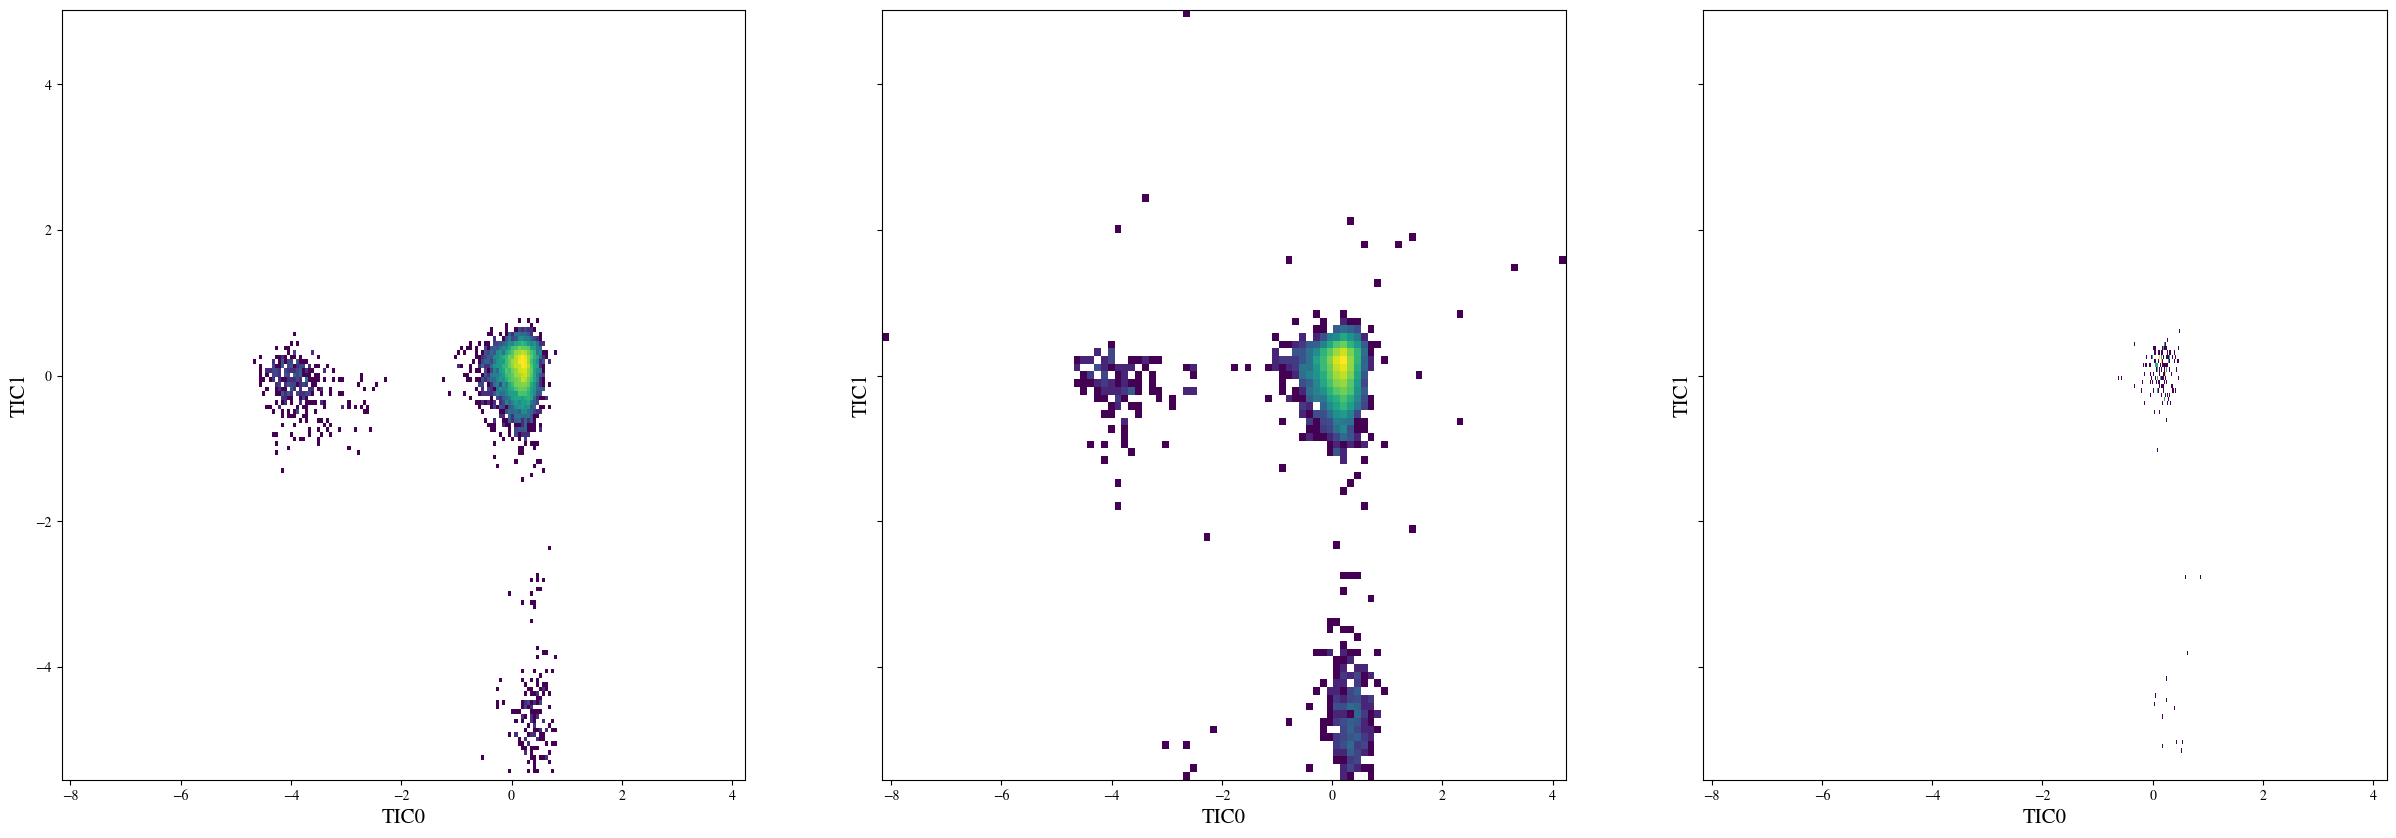

In [36]:
import mdtraj as md
from src.data.preprocessing.tica import tica_features
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def plot_tic01(ax, tics, ylims, xlims, cmap="viridis"):
    _ = ax.hist2d(tics[:, 0], tics[:, 1], bins=100, norm=LogNorm(), cmap=cmap)
    ax.set_xlabel("TIC0", fontsize=15)
    ax.set_ylabel("TIC1", fontsize=15)
    ax.set_ylim(ylims[0], ylims[1])
    ax.set_xlim(xlims[0], xlims[1])
    # ax.set_xticks([])
    # ax.set_yticks([])
    return ax

# I need unnormalised samples
true_md_traj = md.Trajectory(md_ref.cpu().numpy(), topology=dm.topology)
true_features = tica_features(true_md_traj)

simple_proposal_traj = md.Trajectory(proposal_positions.cpu().numpy(), topology=dm.topology)
simple_proposal_features = tica_features(simple_proposal_traj)

wmd_proposal_traj = md.Trajectory(proposal_md_positions.cpu().numpy(), topology=dm.topology)
wmd_proposal_features = tica_features(wmd_proposal_traj)


tics_true = tica_model.transform(true_features)
tics_simple = tica_model.transform(simple_proposal_features)
tics_md = tica_model.transform(wmd_proposal_features)

ylims = (min(tics_true[:, 1].min(), tics_simple[:, 1].min(), tics_md[:, 1].min()), max(tics_true[:, 1].max(), tics_simple[:, 1].max(), tics_md[:, 1].max()))
xlims = (min(tics_true[:, 0].min(), tics_simple[:, 0].min(), tics_md[:, 0].min()), max(tics_true[:, 0].max(), tics_simple[:, 0].max(), tics_md[:, 0].max()))

for tics in [tics_true, tics_simple, tics_md]:
    if isinstance(tics, torch.Tensor):
        tics = tics.cpu().numpy()

fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(30, 10))
ax[0] = plot_tic01(ax[0], tics_true, ylims, xlims)
ax[1] = plot_tic01(ax[1], tics_simple, ylims, xlims)
ax[2] = plot_tic01(ax[2], tics_md, ylims, xlims)


In [33]:
tics_simple

array([[0.22555295, 0.20559696],
       [0.13147583, 0.46575675],
       [0.32881522, 0.14244425],
       ...,
       [0.12316209, 0.15310963],
       [0.31797406, 0.30139386],
       [0.16130738, 0.01586133]], shape=(9952, 2))

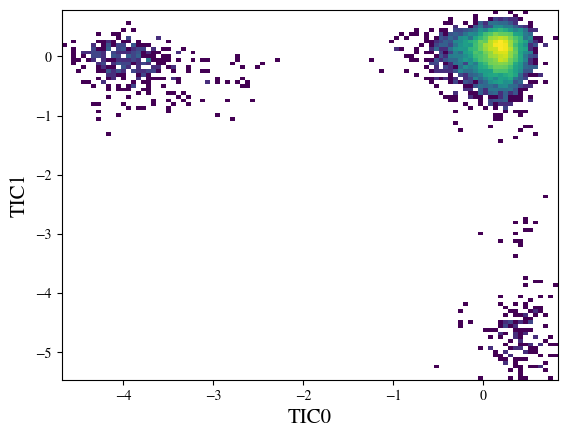

In [27]:
fig, ax = plt.subplots()
ax = plot_tic01(ax, tics_true)

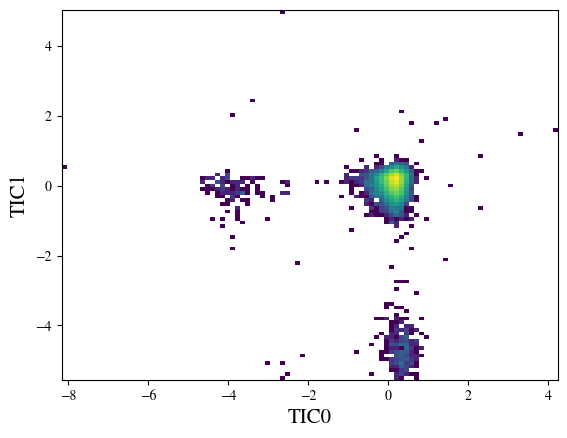

In [28]:
fig, ax = plt.subplots()
ax = plot_tic01(ax, tics_simple)

In [31]:
(2,3).min()

AttributeError: 'tuple' object has no attribute 'min'

In [12]:
true_features = tica_features(true_md_traj)
true_features_1 = tica_features(true_md_traj_1)

In [13]:
true_features

array([[ 0.51646733,  0.8579544 ,  0.84097576, ..., -0.9901816 ,
        -0.99982655, -0.9982107 ],
       [ 0.50057936,  0.84118766,  0.86801964, ..., -0.9983237 ,
        -0.99850494, -0.93278515],
       [ 0.500436  ,  0.81817824,  0.8269243 , ..., -0.97453284,
        -0.9401803 , -0.9902296 ],
       ...,
       [ 0.50094694,  0.8273958 ,  0.8601552 , ..., -0.9754004 ,
        -0.98395306, -0.9985148 ],
       [ 0.50819916,  0.85947484,  0.83688307, ..., -0.99032307,
        -0.9968884 , -0.99862474],
       [ 0.5019492 ,  0.8398489 ,  0.8506945 , ..., -0.9962648 ,
        -0.9650474 , -0.9979353 ]], shape=(10000, 306), dtype=float32)

In [14]:
true_features_1

array([[ 0.15421398,  0.25617993,  0.2511102 , ..., -0.9901816 ,
        -0.99982655, -0.9982107 ],
       [ 0.14946994,  0.25117347,  0.2591853 , ..., -0.9983237 ,
        -0.99850494, -0.93278515],
       [ 0.14942712,  0.24430299,  0.24691452, ..., -0.9745328 ,
        -0.9401804 , -0.9902296 ],
       ...,
       [ 0.1495797 ,  0.2470553 ,  0.2568371 , ..., -0.9754004 ,
        -0.98395306, -0.9985148 ],
       [ 0.15174514,  0.2566339 ,  0.24988817, ..., -0.99032307,
        -0.9968884 , -0.99862474],
       [ 0.14987896,  0.2507737 ,  0.25401214, ..., -0.9962648 ,
        -0.96504736, -0.9979353 ]], shape=(10000, 306), dtype=float32)